In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/cleaned_churn.csv")

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Churn rate:", df["Churn"].mean())

Shape: (7043, 20)
Missing values: 0
Churn rate: 0.2653698707936959


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [4]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

categorical_cols= df.select_dtypes(include=['string','object','category']).columns.tolist()

print(numeric_cols)
print(categorical_cols)

['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


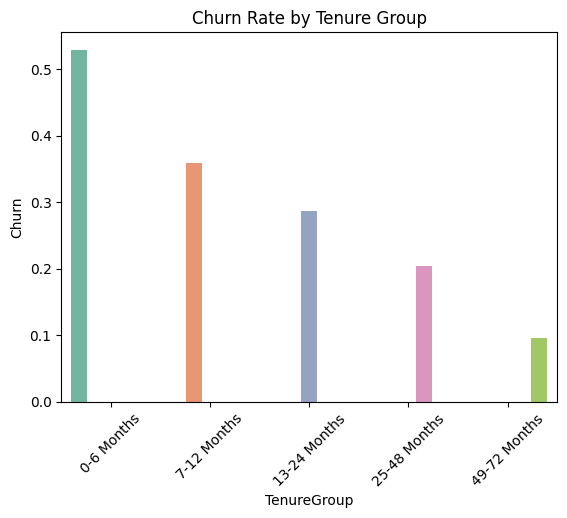

In [7]:
df["TenureGroup"]= pd.cut(
    df["tenure"],
    bins=[-1,6,12,24,48,72],
    labels=[
        '0-6 Months',
        '7-12 Months',
        '13-24 Months',
        '25-48 Months',
        '49-72 Months'
    ]
)

sns.barplot(
    data=df,
    x="TenureGroup",
    y="Churn",
    hue="TenureGroup",
    palette="Set2",
    legend=False,
    errorbar=None
)

plt.xticks(rotation=45)
plt.title("Churn Rate by Tenure Group")
plt.show()

In [8]:
service_cols = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["TotalServices"] = (df[service_cols] == "Yes").sum(axis=1)

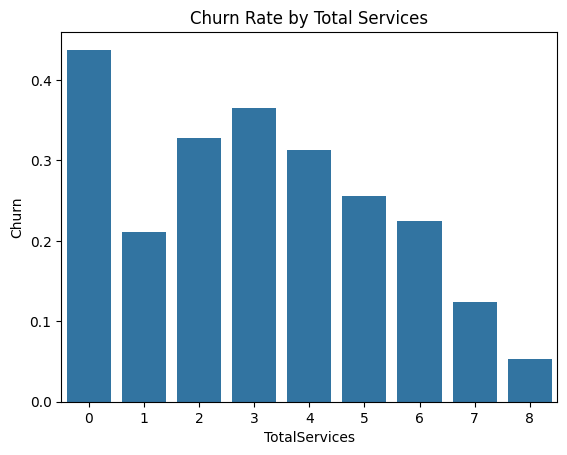

In [9]:
sns.barplot(
    data=df,
    x="TotalServices",
    y="Churn",
    errorbar=None
)

plt.title("Churn Rate by Total Services")
plt.show()

In [10]:
df["AverageMonthlySpend"] = (
    df["TotalCharges"] / df["tenure"].replace(0, np.nan)
)

df["AverageMonthlySpend"] = df["AverageMonthlySpend"].fillna(
    df["MonthlyCharges"]
)

In [11]:
df["IsNewCustomer"] = (df["tenure"] <= 6).astype(int)

In [12]:
df["HasSupport"] = (
    (df["TechSupport"] == "Yes") |
    (df["OnlineSecurity"] == "Yes")
).astype(int)

In [14]:
df["HasFamily"] = (
    (df["Partner"] == "Yes") |
    (df["Dependents"] == "Yes")
).astype(int)

In [13]:
df["ChargesPerService"] = (
    df["MonthlyCharges"] /
    df["TotalServices"].clip(lower=1)
)

In [15]:
new_features = [
    "TenureGroup",
    "TotalServices",
    "AverageMonthlySpend",
    "IsNewCustomer",
    "HasSupport",
    "HasFamily",
    "ChargesPerService"
]

df[new_features].head(10)

,TenureGroup,TotalServices,AverageMonthlySpend,IsNewCustomer,HasSupport,HasFamily,ChargesPerService
0,0-6 Months,1,29.850000,1,0,1,29.850000
1,25-48 Months,3,55.573529,0,1,0,18.983333
2,0-6 Months,3,54.075000,1,1,0,17.950000
3,25-48 Months,3,40.905556,0,1,0,14.100000
4,0-6 Months,1,75.825000,1,0,0,70.700000
5,7-12 Months,5,102.562500,0,0,0,19.930000
6,13-24 Months,4,88.609091,0,0,1,22.275000
7,7-12 Months,1,30.190000,0,1,0,29.750000
8,25-48 Months,6,108.787500,0,1,1,17.466667
9,49-72 Months,3,56.257258,0,1,1,18.716667


In [16]:
print(df.isnull().sum())

print(
    np.isinf(
        df.select_dtypes(include="number")
    ).sum()
)

print(df.shape)

gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity         0
OnlineBackup           0
DeviceProtection       0
TechSupport            0
StreamingTV            0
StreamingMovies        0
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
Churn                  0
TenureGroup            0
TotalServices          0
AverageMonthlySpend    0
IsNewCustomer          0
HasSupport             0
ChargesPerService      0
HasFamily              0
dtype: int64
tenure                 0
MonthlyCharges         0
TotalCharges           0
Churn                  0
TotalServices          0
AverageMonthlySpend    0
IsNewCustomer          0
HasSupport             0
ChargesPerService      0
HasFamily              0
dtype: int64
(7043, 27)


In [17]:
df.to_csv(
    "../data/processed/engineered_churn.csv",
    index=False
)